Part I - Constructing the Kalman Filter: From Model to Real-Time Tracking

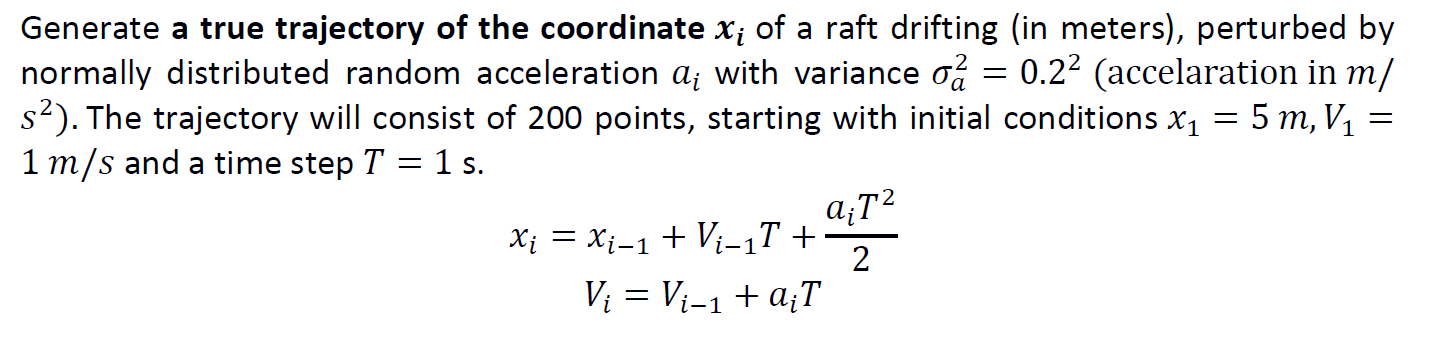

In [19]:
import numpy as np
from matplotlib import pyplot as plt

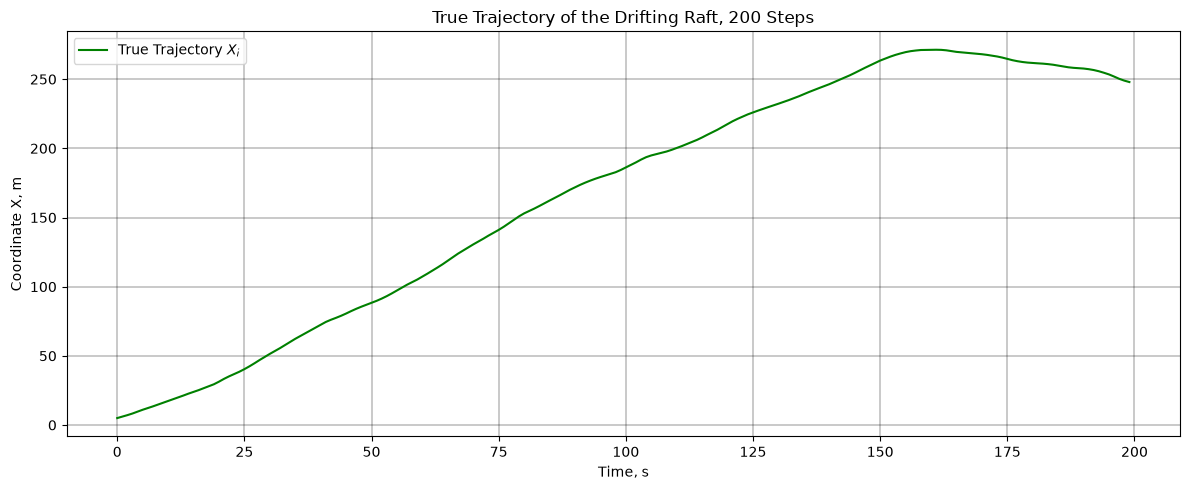

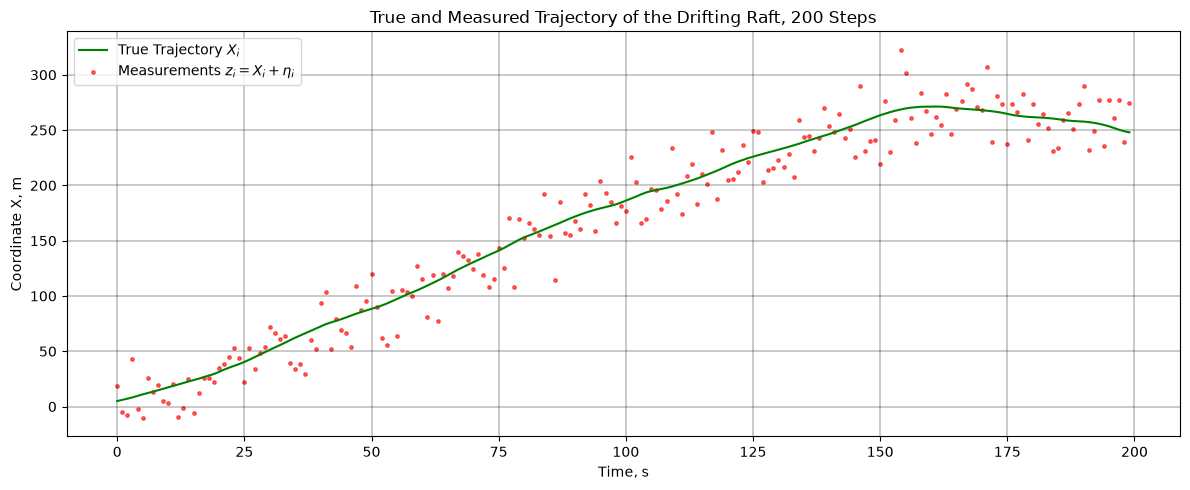

In [20]:
#generating a true tragectory of a raft drifting with a random acceleration
# save generated trajectories so the whole team works on the same data
from pathlib import Path

output_dir = Path("common_files")
output_dir.mkdir(parents=True, exist_ok=True)

# constants for trajectory modelling of the drifting raft
SIZE = 200
INITIAL_COORDINATE_M = 5
INITIAL_VELOCITY_M_S = 1
T = 1

VARIANCE_A = 0.2**2
SIGMA_A = np.sqrt(VARIANCE_A)

VARIANCE_ETA = 20**2
SIGMA_ETA = np.sqrt(VARIANCE_ETA)

# a function to generate a true trajectory of a drifting raft using the random acceleration model
def generate_true_trajectory(size, init_coord, init_velocity, sigma_a, t):
    traj_points = np.zeros(size)
    velocity_points = np.zeros(size)
    traj_points[0] = init_coord
    velocity_points[0] = init_velocity

    for i in range(1, size):
        acceleration = np.random.normal(loc=0.0, scale=sigma_a)
        traj_points[i] = traj_points[i-1] + velocity_points[i-1] * t + acceleration * t**2 / 2
        velocity_points[i] = velocity_points[i-1] + acceleration * t

    return traj_points, velocity_points

# a function to generate measured trajectory points based on the true trajectory
def generate_measured_trajectory(true_trajectory, sigma_eta):
    measured_trajectory = true_trajectory.copy()
    return measured_trajectory + np.random.normal(0.0, sigma_eta, size=measured_trajectory.size)

# a function to plot a true trajectory
def plot_true_trajectory(true_traj, title, step_size=1):
    steps = np.arange(true_traj.size * step_size, step = step_size)
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(steps, true_traj, color="green", linewidth=1.5, label="True Trajectory $X_i$")
    ax.set_title(title)
    ax.set_xlabel("Time, s")
    ax.set_ylabel("Coordinate X, m")
    ax.grid(True, color="black", linewidth=0.3)
    ax.legend(frameon=True)
    fig.tight_layout()
    plt.show()

# a function to plot a true trajectory and measured points
def plot_true_vs_measured(true_traj, measured_traj, title, step_size=1):
    steps = np.arange(true_traj.size * step_size, step = step_size)
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(steps, true_traj, color="green", linewidth=1.5, label="True Trajectory $X_i$")
    ax.scatter(steps, measured_traj, color="red", s=6, alpha=0.6, label="Measurements $z_i = X_i + \\eta_i$")
    ax.set_title(title)
    ax.set_xlabel("Time, s")
    ax.set_ylabel("Coordinate X, m")
    ax.grid(True, color="black", linewidth=0.3)
    ax.legend(frameon=True)
    fig.tight_layout()
    plt.show()

# a function to plot a true trajectory, measured points and the filtered estimate
def plot_filter_results(true_traj, measured_traj, estimated_traj, title, step_size=1):
    steps = np.arange(true_traj.size * step_size, step = step_size)
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(steps, true_traj, color="green", linewidth=1.5, label="True Trajectory $X_i$")
    ax.scatter(steps, measured_traj, color="red", s=6, alpha=0.6, label="Measurements $z_i = X_i + \\eta_i$")
    ax.plot(steps, estimated_traj, color="blue", linewidth=1.5, label="Kalman Filter Estimate $\\hat{x}_{i,i}$")
    ax.set_title(title)
    ax.set_xlabel("Time, s")
    ax.set_ylabel("Coordinate X, m")
    ax.grid(True, color="black", linewidth=0.3)
    ax.legend(frameon=True)
    fig.tight_layout()
    plt.show()

# generate the trajectories 
#true_trajectory_raft, true_velocity_raft = generate_true_trajectory(SIZE, INITIAL_COORDINATE_M, INITIAL_VELOCITY_M_S, SIGMA_A, T)
#measured_trajectory_raft = generate_measured_trajectory(true_trajectory_raft, SIGMA_ETA)

# save the trajectories (uncomment only after checking the plots)
#np.savetxt(output_dir / "true_trajectory_raft.txt", true_trajectory_raft)
#np.savetxt(output_dir / "true_velocity_raft.txt", true_velocity_raft)
#np.savetxt(output_dir / "measured_trajectory_raft.txt", measured_trajectory_raft)

# load the trajectories shared within the team
true_trajectory_raft = np.loadtxt(output_dir / "true_trajectory_raft.txt")
true_velocity_raft = np.loadtxt(output_dir / "true_velocity_raft.txt")
measured_trajectory_raft = np.loadtxt(output_dir / "measured_trajectory_raft.txt")

# plot the trajectories
plot_true_trajectory(true_trajectory_raft, "True Trajectory of the Drifting Raft, 200 Steps", step_size=T)
plot_true_vs_measured(true_trajectory_raft, measured_trajectory_raft, "True and Measured Trajectory of the Drifting Raft, 200 Steps", step_size=T)

Representing the dynamical system in state space 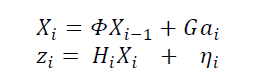

In [21]:
# state-space model of the drifting raft
# transition matrix Phi
PHI = np.array([[1, T],
                [0, 1]])

# input matrix G that defines how the random acceleration a_i influences the state vector
G = np.array([[T**2 / 2],
              [T]])

# observation matrix H that relates the measurement vector to the state vector 
H = np.array([[1, 0]])

# covariance matrix Q of the state noise G * a_i
Q = G @ G.T * VARIANCE_A

# covariance matrix R of the measurement noise
R = np.array([[VARIANCE_ETA]])

Developing a kalman Filter includes next steps: 0. Initialization 1. Prediction 2. Filtration  

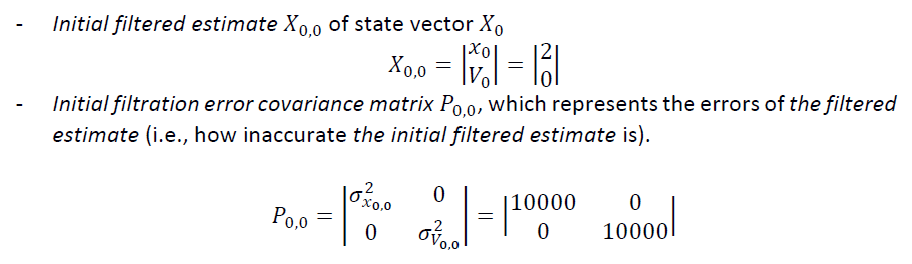

In [22]:
#setting the initial conditions for the filtered estimate and the filtration error covariance matrix
# initial filtered estimate X_{0,0} of the state vector [x, V]
X_0_0 = np.array([[2],
                  [0]])
# initial filtration error covariance matrix P_{0,0}
P_0_0 = np.array([[10000, 0],
                  [0, 10000]])


In [23]:
# Kalman filter as a function
def kalman_filter(measurements, phi, h, q, r, x_0_0, p_0_0):
    size = measurements.size

    # arrays to store the results of the filter at every step i
    x_pred = np.zeros((size, 2, 1))   # predicted state X_{i,i-1}
    p_pred = np.zeros((size, 2, 2))   # prediction error covariance P_{i,i-1}
    x_filt = np.zeros((size, 2, 1))   # filtered state X_{i,i}
    p_filt = np.zeros((size, 2, 2))   # filtration error covariance P_{i,i}
    k = np.zeros((size, 2, 1))        # filter gain K_i

    identity = np.eye(2)
    x_prev = x_0_0
    p_prev = p_0_0

    for i in range(size):
        # prediction
        x_pred[i] = phi @ x_prev
        p_pred[i] = phi @ p_prev @ phi.T + q

        # filtration
        k[i] = p_pred[i] @ h.T @ np.linalg.inv(h @ p_pred[i] @ h.T + r)
        x_filt[i] = x_pred[i] + k[i] * (measurements[i] - h @ x_pred[i])
        p_filt[i] = (identity - k[i] @ h) @ p_pred[i]

        x_prev = x_filt[i]
        p_prev = p_filt[i]

    return x_pred, p_pred, x_filt, p_filt, k

5) Plot the results, including the true trajectory, measurements, and filtered estimates of the state vector 𝑋𝑖.

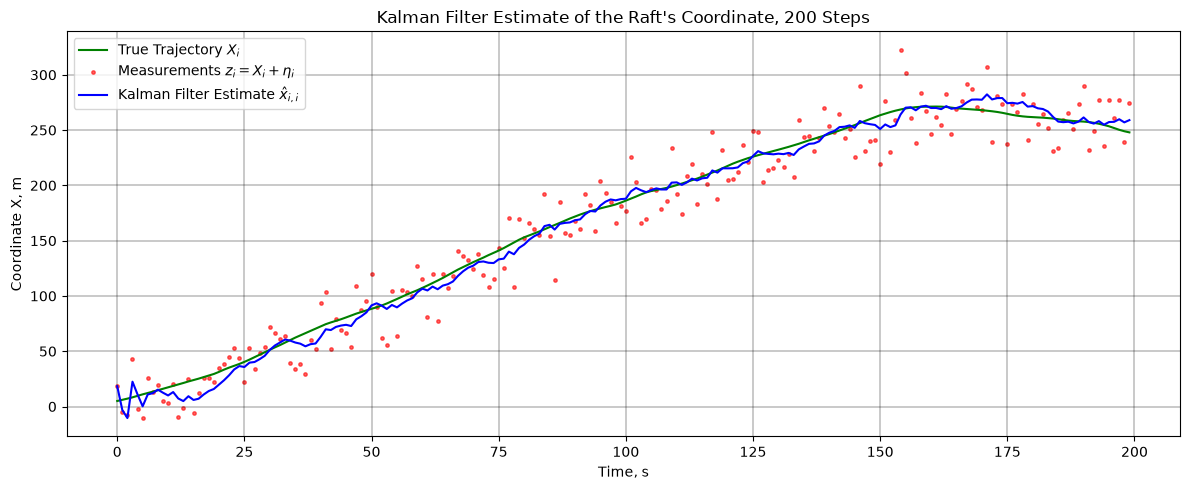

In [24]:
#Kalman filter for measured trag
x_pred, P_pred, x_filt, P_filt, K = kalman_filter(measured_trajectory_raft, PHI, H, Q, R, X_0_0, P_0_0)

# plot the true trajectory, measurements and the filtered estimate
plot_filter_results(true_trajectory_raft, measured_trajectory_raft, x_filt[:, 0, 0],
                    "Kalman Filter Estimate of the Raft's Coordinate, 200 Steps", step_size=T)

Run the filter multiple times to observe how the estimation results vary with each new trajectory.

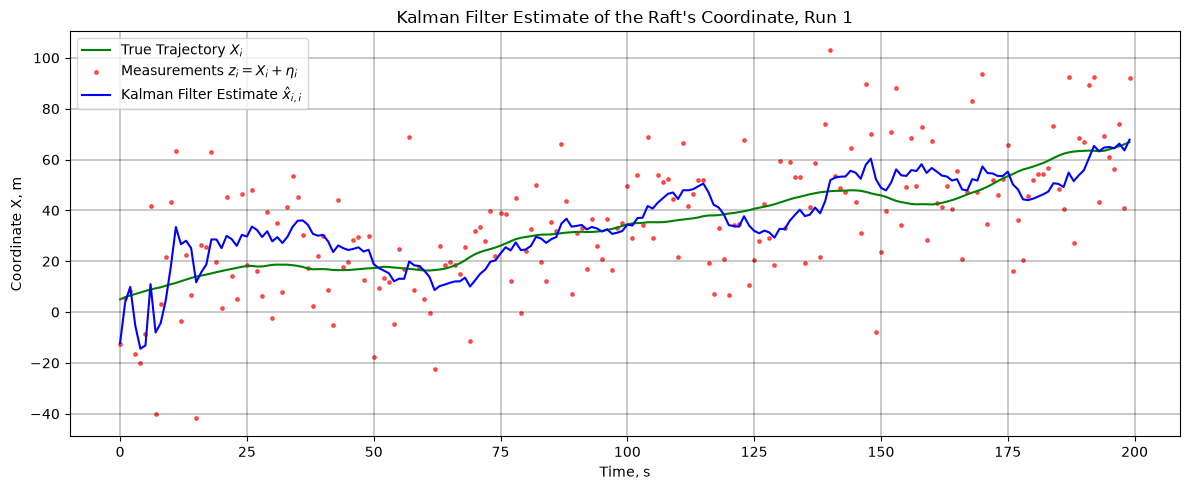

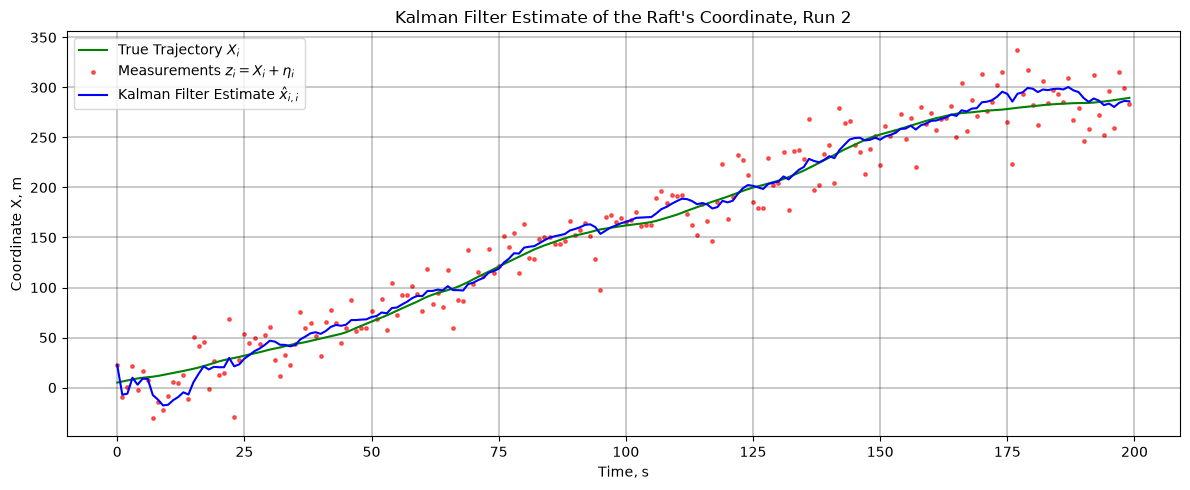

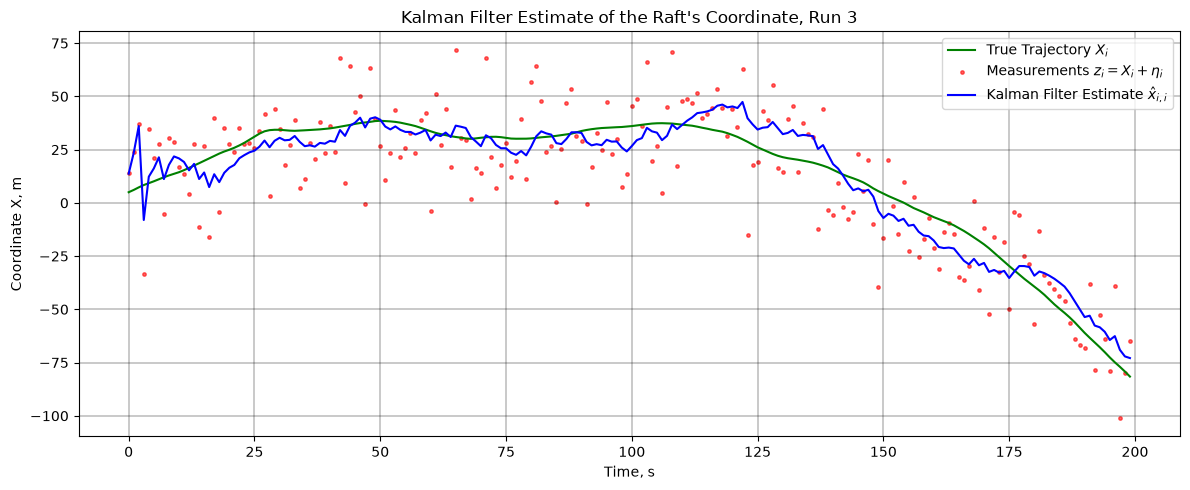

In [25]:
# run the filter several times with new trajectories and new measurements
for run in range(3):
    true_traj_run, true_vel_run = generate_true_trajectory(SIZE, INITIAL_COORDINATE_M, INITIAL_VELOCITY_M_S, SIGMA_A, T)
    measured_traj_run = generate_measured_trajectory(true_traj_run, SIGMA_ETA)
    _, _, x_filt_run, _, _ = kalman_filter(measured_traj_run, PHI, H, Q, R, X_0_0, P_0_0)

    plot_filter_results(true_traj_run, measured_traj_run, x_filt_run[:, 0, 0],
                        f"Kalman Filter Estimate of the Raft's Coordinate, Run {run + 1}", step_size=T)

6)Analysis of filter gain 𝑲𝒊 and estimation errors in the filtered state vector 𝑿𝒊.

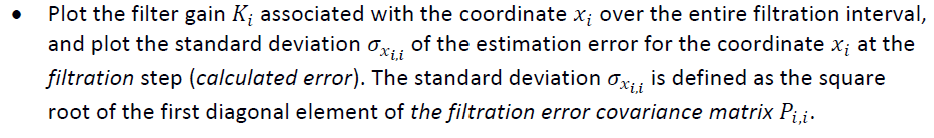

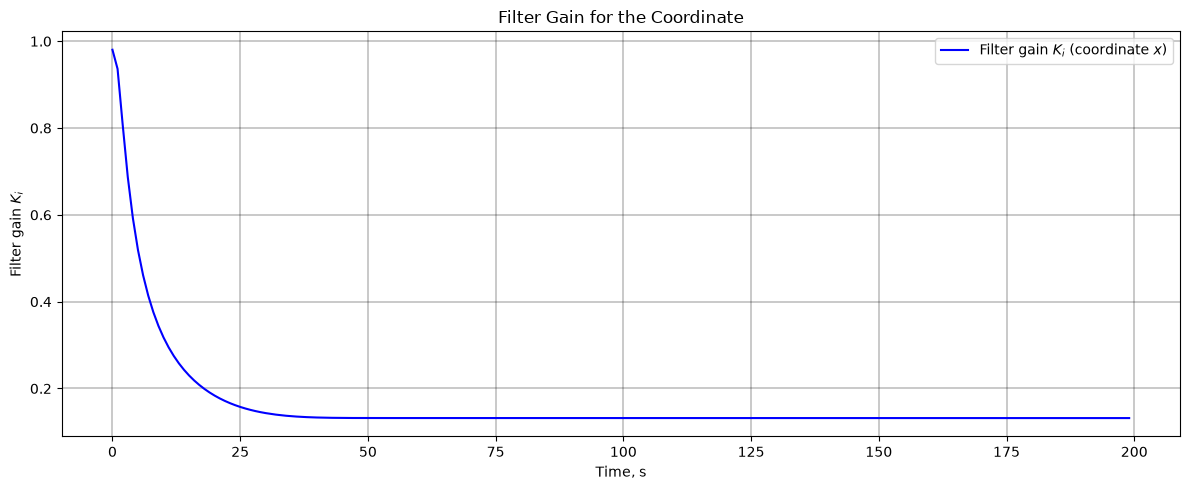

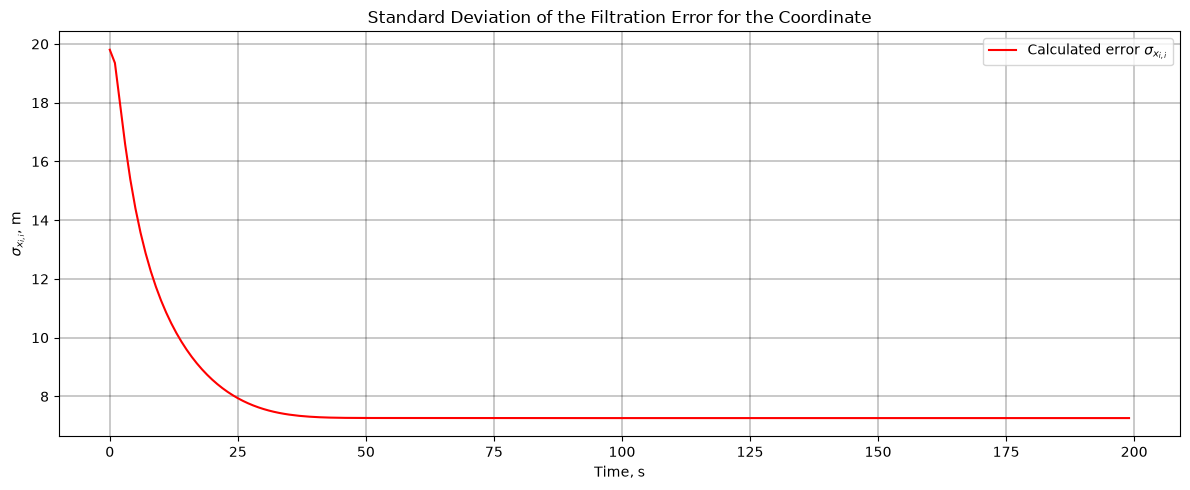

In [26]:
# filter gain for the coordinate x and standard deviation of the filtration error
steps = np.arange(SIZE * T, step = T)
K_x = K[:, 0, 0]                    # gain associated with the coordinate x
sigma_x_filt = np.sqrt(P_filt[:, 0, 0])   # sqrt of the first diagonal element of P_{i,i}

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(steps, K_x, color="blue", linewidth=1.5, label="Filter gain $K_i$ (coordinate $x$)")
ax.set_title("Filter Gain for the Coordinate")
ax.set_xlabel("Time, s")
ax.set_ylabel("Filter gain $K_i$")
ax.grid(True, color="black", linewidth=0.3)
ax.legend(frameon=True)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(steps, sigma_x_filt, color="red", linewidth=1.5, label="Calculated error $\\sigma_{x_{i,i}}$")
ax.set_title("Standard Deviation of the Filtration Error for the Coordinate")
ax.set_xlabel("Time, s")
ax.set_ylabel("$\\sigma_{x_{i,i}}$, m")
ax.grid(True, color="black", linewidth=0.3)
ax.legend(frameon=True)
fig.tight_layout()
plt.show()

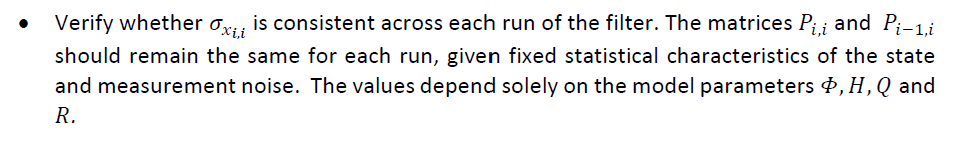

In [27]:
# run the filter on two different realizations and compare P_{i,i} and K
_, _, _, P_filt_1, K_1 = kalman_filter(generate_measured_trajectory(generate_true_trajectory(SIZE, INITIAL_COORDINATE_M, INITIAL_VELOCITY_M_S, SIGMA_A, T)[0], SIGMA_ETA), PHI, H, Q, R, X_0_0, P_0_0)
_, _, _, P_filt_2, K_2 = kalman_filter(generate_measured_trajectory(generate_true_trajectory(SIZE, INITIAL_COORDINATE_M, INITIAL_VELOCITY_M_S, SIGMA_A, T)[0], SIGMA_ETA), PHI, H, Q, R, X_0_0, P_0_0)

print(np.allclose(P_filt_1, P_filt_2), np.allclose(K_1, K_2))

True True


не читала)))  Consistency across runs. For two different realizations of the trajectory and measurements, the matrices $P_{i,i}$ and the gains $K_i$ coincide (np.allclose returns True for both). The filtration error covariance and the gain are computed from $\Phi$, $H$, $Q$, $R$ and $P_{0,0}$ only; they do not depend on the measurements $z_i$ or on the true trajectory. Therefore the calculated error $\sigma_{x_{i,i}}$ can be computed in advance, before any measurements are received.

Convergence. The gain for the coordinate decreases from about 0.98 at the first step and reaches a constant value of about 0.13 after roughly 40–50 s; the standard deviation $\sigma_{x_{i,i}}$ decreases from about 20 m to about 7.3 m and stays there. After this moment new measurements no longer improve the accuracy of the estimate: in the presence of random accelerations the raft’s motion cannot be predicted exactly, so there is a limit of accuracy that the filter cannot go below. At this stage the filter becomes stationary and a constant gain can be used instead of recomputing it at every step.

Dimension of the gain. $K_i$ has dimension $n \times m$, where $n = 2$ is the dimension of the state vector and $m = 1$ is the dimension of the measurement vector, so here it is a $2 \times 1$ matrix.

Predictions of future states of the drifting raft.

In [28]:
# predictions m-1 steps ahead from the filtered estimate X_{i,i}
M_PRED = 7

# transition matrix over m-1 steps: Phi multiplied by itself m-1 times
PHI_M = np.linalg.matrix_power(PHI, M_PRED - 1)

# X_{i+m-1,i} = Phi_{i+m-1,i} * X_{i,i} for every step i
x_pred_m = np.zeros((SIZE, 2, 1))
for i in range(SIZE):
    x_pred_m[i] = PHI_M @ x_filt[i]

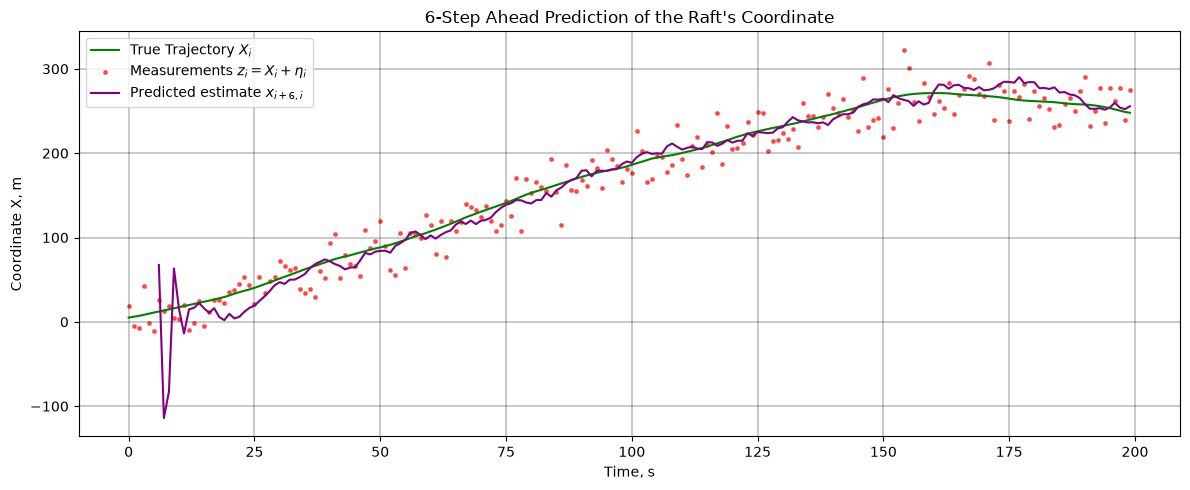

In [29]:
steps = np.arange(SIZE * T, step = T)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(steps, true_trajectory_raft, color="green", linewidth=1.5, label="True Trajectory $X_i$")
ax.scatter(steps, measured_trajectory_raft, color="red", s=6, alpha=0.6, label="Measurements $z_i = X_i + \\eta_i$")
ax.plot(steps[M_PRED - 1:], x_pred_m[:SIZE - (M_PRED - 1), 0, 0], color="purple", linewidth=1.5,
        label=f"Predicted estimate $x_{{i+{M_PRED - 1},i}}$")
ax.set_title(f"{M_PRED - 1}-Step Ahead Prediction of the Raft's Coordinate")
ax.set_xlabel("Time, s")
ax.set_ylabel("Coordinate X, m")
ax.grid(True, color="black", linewidth=0.3)
ax.legend(frameon=True)
fig.tight_layout()
plt.show()

The predicted estimate $x_{i+6,i}$ follows the general shape of the true trajectory, but it is noisier than the filtered estimate $x_{i,i}$. This happens because the prediction is $x_{i,i} + 6T\,V_{i,i}$, so the error of the velocity estimate is multiplied by six. At the beginning of the observation interval, when the velocity estimate is still very inaccurate, the prediction deviates from the true trajectory by more than 100 m. Near the turning point of the trajectory the prediction overshoots the true trajectory, because it extrapolates the velocity estimated at step $i$, which changes randomly over the next six steps. The farther ahead we predict, the larger the prediction error becomes.

Part 2
Accuracy analysis under optimal and non-optimal conditions.
1-2 Statistical estimation errors

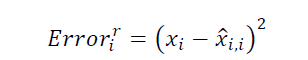

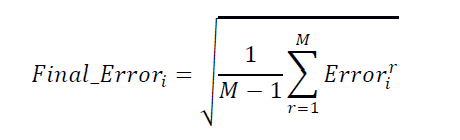

In [30]:
# true estimation errors of the Kalman filter over M runs
M_RUNS = 500
M_PRED = 7
PHI_M = np.linalg.matrix_power(PHI, M_PRED - 1)

def run_experiment(m_runs, sigma_a, q, p_0_0, x_0_0=X_0_0):
    # sigma_a: used to generate the true trajectories; q, p_0_0, x_0_0: used inside the filter
    sq_err_filt = np.zeros((m_runs, SIZE))            # (x_i - x_{i,i})^2
    sq_err_pred1 = np.zeros((m_runs, SIZE))           # (x_i - x_{i,i-1})^2, 1-step ahead prediction
    sq_err_pred_m = np.full((m_runs, SIZE), np.nan)   # (x_i - x_{i,i-m+1})^2, (m-1)-step ahead prediction

    for r in range(m_runs):
        # new true trajectory and new measurements in every run
        true_traj, _ = generate_true_trajectory(SIZE, INITIAL_COORDINATE_M, INITIAL_VELOCITY_M_S, sigma_a, T)
        measured_traj = generate_measured_trajectory(true_traj, SIGMA_ETA)

        x_pred, p_pred, x_filt, p_filt, k = kalman_filter(measured_traj, PHI, H, q, R, x_0_0, p_0_0)

        # (m-1)-step ahead prediction made at step i refers to time i + m - 1
        x_pred_m = np.array([PHI_M @ x_filt[i] for i in range(SIZE)])[:, 0, 0]

        sq_err_filt[r] = (true_traj - x_filt[:, 0, 0])**2
        sq_err_pred1[r] = (true_traj - x_pred[:, 0, 0])**2
        sq_err_pred_m[r, M_PRED - 1:] = (true_traj[M_PRED - 1:] - x_pred_m[:SIZE - (M_PRED - 1)])**2

    # root of the sum over runs divided by (M - 1), as in the assignment
    final_err_filt = np.sqrt(np.sum(sq_err_filt, axis=0) / (m_runs - 1))
    final_err_pred1 = np.sqrt(np.sum(sq_err_pred1, axis=0) / (m_runs - 1))
    final_err_pred_m = np.sqrt(np.sum(sq_err_pred_m, axis=0) / (m_runs - 1))
    return final_err_filt, final_err_pred1, final_err_pred_m

In [31]:


# a function to plot several error curves on one figure
def plot_errors(curves, title, step_size=1, start=2, sigma_eta=None, ylabel="Estimation error, m"):
    # curves: list of (values, label, color)
    steps = np.arange(len(curves[0][0]) * step_size, step = step_size)
    fig, ax = plt.subplots(figsize=(12, 5))
    for values, label, color in curves:
        ax.plot(steps[start:], values[start:], color=color, linewidth=1.5, label=label)
    if sigma_eta is not None:
        ax.axhline(sigma_eta, color="red", linestyle="--", linewidth=1, label="Measurement error $\\sigma_\\eta$")
    ax.set_title(title)
    ax.set_xlabel("Time, s")
    ax.set_ylabel(ylabel)
    ax.grid(True, color="black", linewidth=0.3)
    ax.legend(frameon=True)
    fig.tight_layout()
    plt.show()



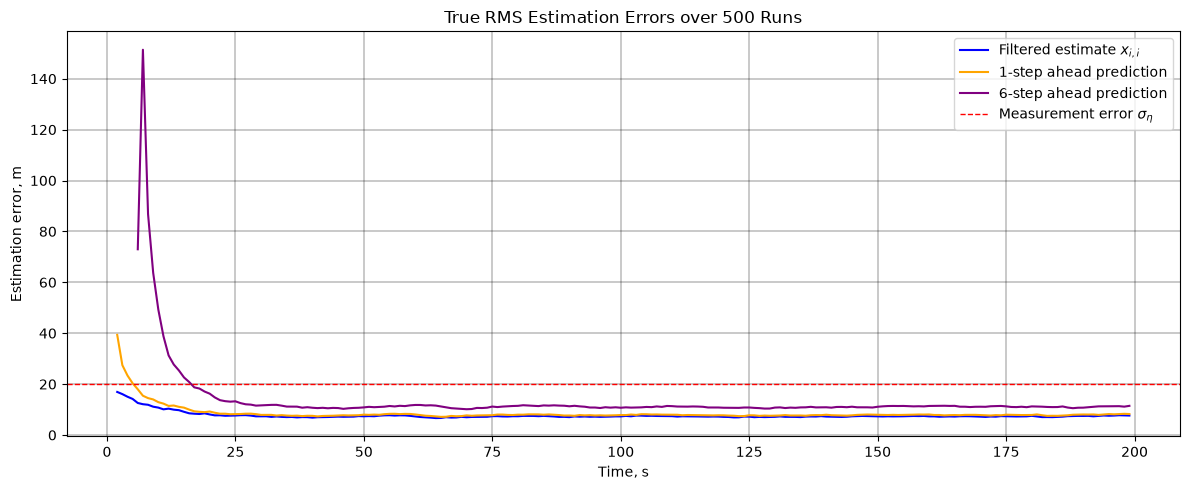

In [32]:
final_err_filt, final_err_pred1, final_err_pred_m = run_experiment(M_RUNS, SIGMA_A, Q, P_0_0)

plot_errors(
    [(final_err_filt, "Filtered estimate $x_{i,i}$", "blue"),
     (final_err_pred1, "1-step ahead prediction", "orange"),
     (final_err_pred_m, f"{M_PRED - 1}-step ahead prediction", "purple")],
    "True RMS Estimation Errors over 500 Runs",
    step_size=T, sigma_eta=SIGMA_ETA)

1. На каком уровне синяя кривая успокаивается (steady_filt). Кривая немного дрожит, поэтому берём среднее по последним 100 шагам. По графику это примерно 7-8 м. Это ответ на вопрос «какова точность фильтра, когда он вышел на постоянный режим».

2. Во сколько раз это меньше 20 м (SIGMA_ETA / steady_filt). Это деление 20 на число из пункта 1. Например, если получилось 7.5, то 20 / 7.5 ≈ 2.7, то есть фильтр примерно в 2.7 раза точнее одного измерения. Это ответ на вопрос задания «меньше ли ошибка, чем σ_η, и на сколько».

3. Когда кривая перестаёт меняться (step_const). Ищем первый шаг, на котором синяя кривая отличается от установившегося уровня меньше чем на 5%. Это ответ на вопрос задания «когда ошибка почти постоянна».

In [33]:
# steady-state values: mean over the last 100 steps
steady_filt = np.mean(final_err_filt[-100:])
steady_pred1 = np.mean(final_err_pred1[-100:])
steady_pred_m = np.mean(final_err_pred_m[-100:])

print(f"Filtered: {steady_filt:.2f} m, 1-step: {steady_pred1:.2f} m, {M_PRED - 1}-step: {steady_pred_m:.2f} m")
print(f"sigma_eta / filtered error = {SIGMA_ETA / steady_filt:.2f}")

# step at which the filtered error gets within 5% of its steady value
step_const = np.where(np.abs(final_err_filt[start:] - steady_filt) < 0.05 * steady_filt)[0][0] + start
print(f"Filtered error becomes almost constant at step {step_const} (t = {step_const * T} s)")

Filtered: 7.32 m, 1-step: 7.86 m, 6-step: 11.04 m
sigma_eta / filtered error = 2.73
Filtered error becomes almost constant at step 23 (t = 23 s)


In [34]:
# the step after which the prediction errors stay below sigma_eta
step_pred1_below = np.where(final_err_pred1 >= SIGMA_ETA)[0][-1] + 1
step_pred_m_below = np.where(final_err_pred_m >= SIGMA_ETA)[0][-1] + 1
print(step_pred1_below, step_pred_m_below)

6 17


ЧЕКНУТЬ ЧИСЛА Dynamics of the true error. The true RMS error of the filtered estimate $x_{i,i}$ decreases during the first seconds and becomes almost constant after about 45 s (within 5% of its steady-state value), at the level of 7.13 m. From this moment the accuracy of the filter no longer improves, so the filter is stationary and a constant gain can be used instead of recomputing the gain at every step. The errors of the 1-step ahead and 6-step ahead predictions are larger than the error of the filtered estimate: 7.66 m and 10.81 m in the steady state. The error of the 6-step ahead prediction is the largest, because the error of the velocity estimate is multiplied by 6, and in the first seconds it exceeds 100 m.

Comparison with the measurement error. The steady-state error of the filtered estimate (7.13 m) is smaller than the standard deviation of the measurement errors $\sigma_\eta = 20$ m, by a factor of 2.81. The filter uses the motion model and all previous measurements, so it estimates the coordinate more accurately than a single measurement does. The error of the filtered estimate is below $\sigma_\eta$ already from the first steps, while the 1-step and 6-step ahead predictions become more accurate than the measurements only after 6 s and 17 s respectively.

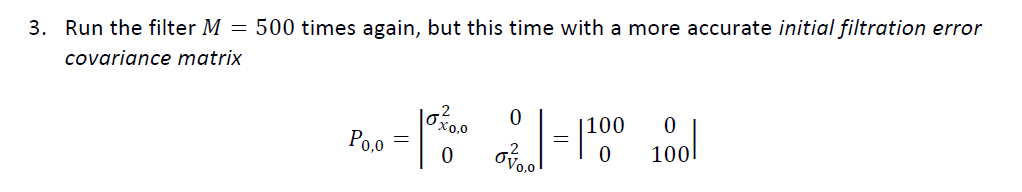

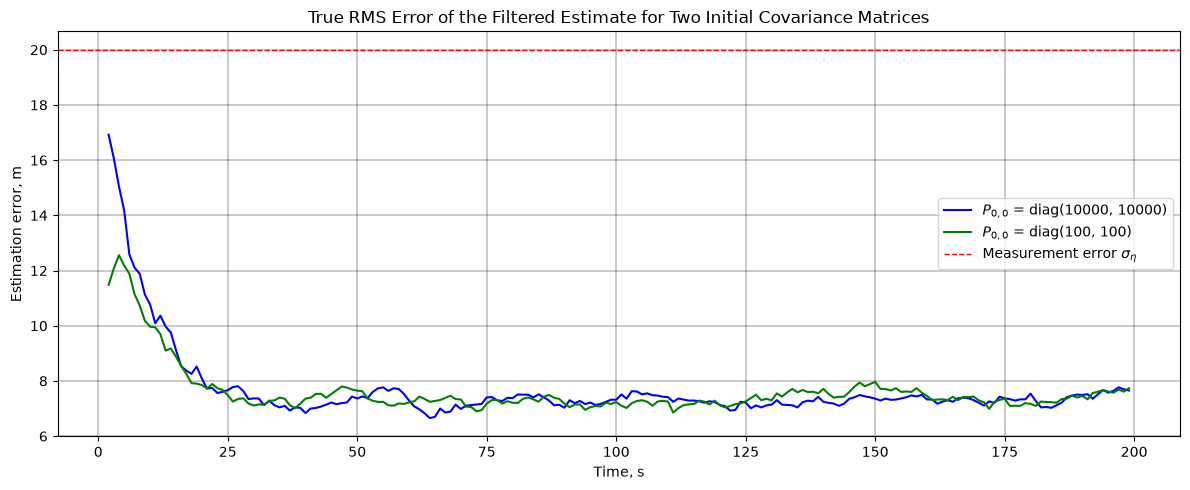

16.92224438799079 11.479825581336204


In [38]:
# the same experiment with a more accurate initial filtration error covariance matrix
P_0_0_ACCURATE = np.array([[100, 0],
                           [0, 100]])

final_err_filt_acc, final_err_pred1_acc, final_err_pred_m_acc = run_experiment(M_RUNS, SIGMA_A, Q, P_0_0_ACCURATE)

# compare the true errors of the filtered estimate for both versions of P_{0,0}
plot_errors(
    [(final_err_filt, "$P_{0,0}$ = diag(10000, 10000)", "blue"),
     (final_err_filt_acc, "$P_{0,0}$ = diag(100, 100)", "green")],
    "True RMS Error of the Filtered Estimate for Two Initial Covariance Matrices",
    step_size=T, sigma_eta=SIGMA_ETA)

# errors at the beginning of the observation interval (i = 3)
print(final_err_filt[2], final_err_filt_acc[2])

Influence of the initial covariance matrix. With the less accurate matrix $P_{0,0} = \mathrm{diag}(10000, 10000)$ the true error of the filtered estimate at the beginning is 16.9 m, while with the more accurate $P_{0,0} = \mathrm{diag}(100, 100)$ it is 11.5 m. The reason is that $P_{0,0}$ tells the filter how much to trust the initial estimate $X_{0,0}$: a very large $P_{0,0}$ makes the filter almost ignore the initial estimate and rely on the first noisy measurements, while a $P_{0,0}$ that matches the real inaccuracy of the initial estimate lets the filter use it with a proper weight. After approximately 20–25 s the two curves coincide, and the remaining differences are of the order of random fluctuations of the estimate over 500 runs. From this moment the initial conditions no longer significantly affect the estimation results, because the filter has accumulated enough measurements, and the steady-state error is determined only by $Q$ and $R$.

4. Comparison of calculated and true estimation errors

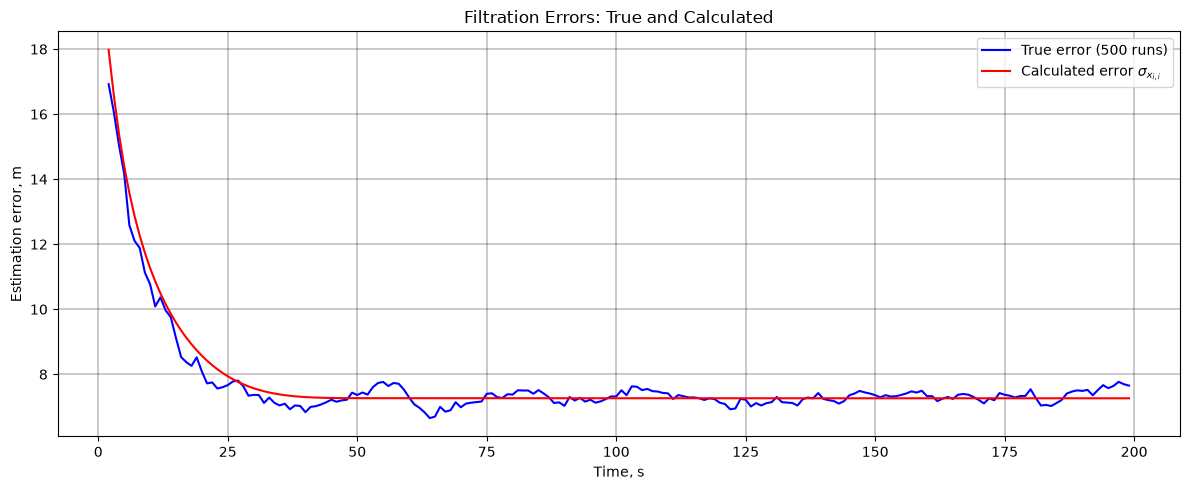

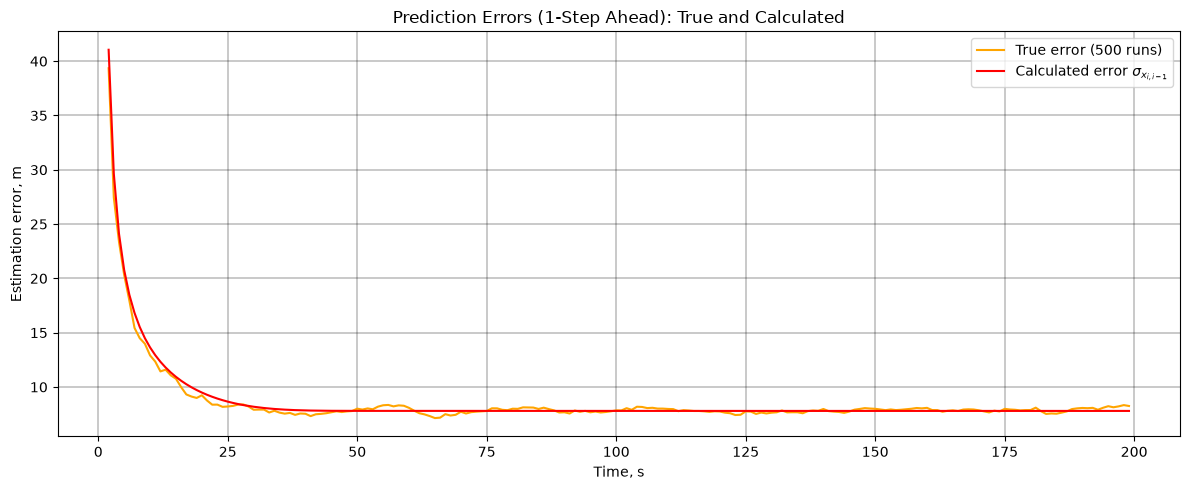

In [39]:
# calculated errors provided by the Kalman filter (depend only on Phi, H, Q, R and P_{0,0})
sigma_x_filt = np.sqrt(P_filt[:, 0, 0])   # sigma_{x_{i,i}}
sigma_x_pred = np.sqrt(P_pred[:, 0, 0])   # sigma_{x_{i,i-1}}

# plot 1: filtration errors
plot_errors(
    [(final_err_filt, "True error (500 runs)", "blue"),
     (sigma_x_filt, "Calculated error $\\sigma_{x_{i,i}}$", "red")],
    "Filtration Errors: True and Calculated",
    step_size=T)

# plot 2: prediction errors (1-step ahead)
plot_errors(
    [(final_err_pred1, "True error (500 runs)", "orange"),
     (sigma_x_pred, "Calculated error $\\sigma_{x_{i,i-1}}$", "red")],
    "Prediction Errors (1-Step Ahead): True and Calculated",
    step_size=T)

In [40]:
print(f"Filtration: calculated {sigma_x_filt[-1]:.2f} m, true {np.mean(final_err_filt[-100:]):.2f} m")
print(f"Prediction: calculated {sigma_x_pred[-1]:.2f} m, true {np.mean(final_err_pred1[-100:]):.2f} m")

Filtration: calculated 7.26 m, true 7.32 m
Prediction: calculated 7.79 m, true 7.86 m


Comparison of calculated and true errors. For both the filtration step and the 1-step ahead prediction step, the calculated errors $\sigma_{x_{i,i}}$ and $\sigma_{x_{i,i-1}}$ provided by the Kalman filter practically coincide with the true errors obtained over 500 runs. In the steady state the calculated filtration error is 7.26 m and the true one is 7.32 m; for the prediction the calculated error is 7.79 m and the true one is 7.86 m. The small fluctuations of the true errors around the calculated ones are caused by the finite number of runs. This correspondence takes place because the filter is tuned properly: the model $\Phi$, $G$, $H$ and the covariance matrices $Q$ and $R$ used in the filter are the same as those used to generate the trajectories and measurements, so the covariance matrices $P_{i,i}$ and $P_{i,i-1}$ describe the real estimation errors.

In practice the true trajectory is unknown, so the true error cannot be computed. However, a properly tuned filter provides the calculated error together with each estimate, and it can be trusted as a measure of the accuracy of the estimate (for example, to decide how safe it is to plan the interception of the raft using the predicted position).

5. Deterministic model and its corresponding filter

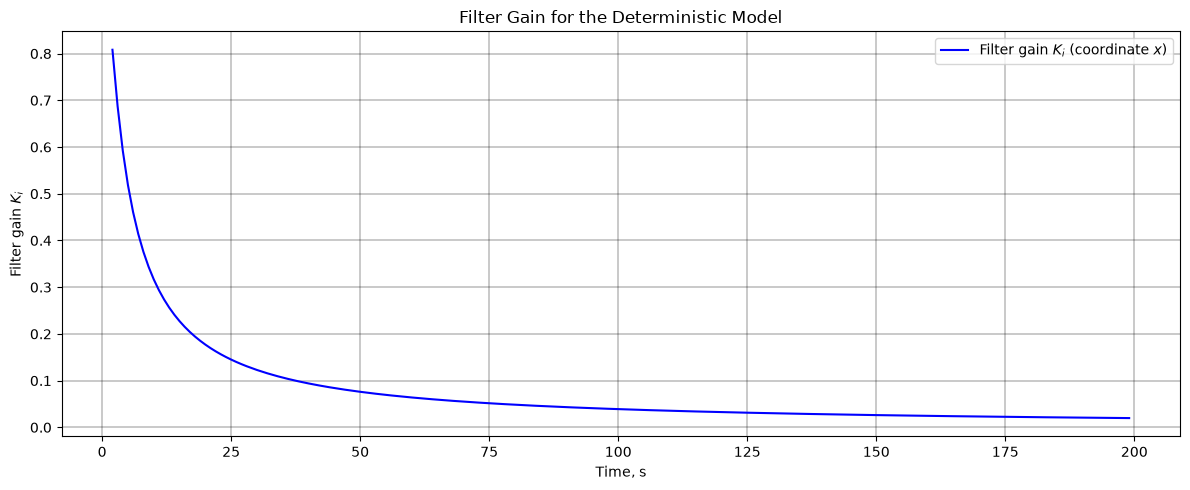

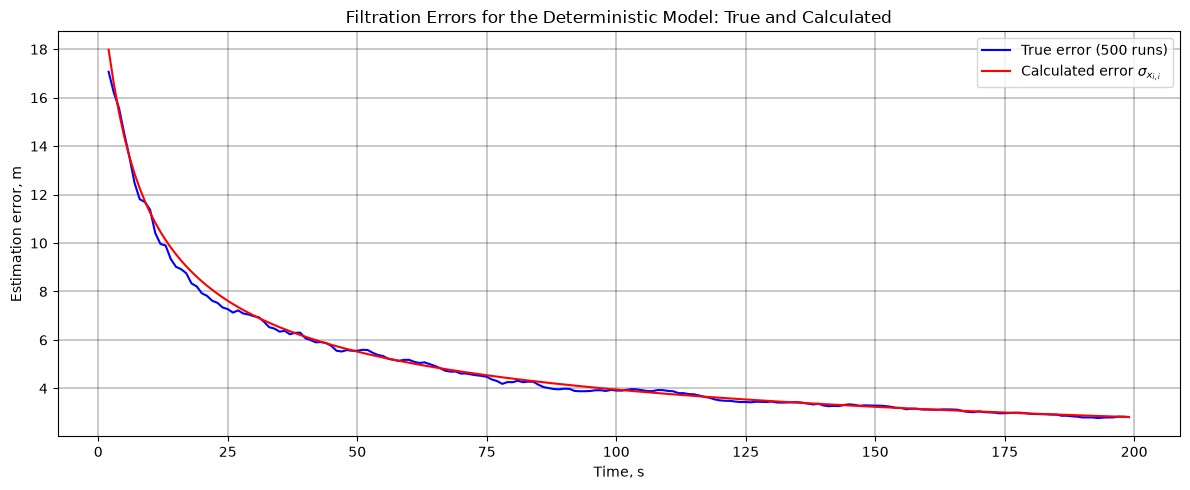

0.019846748599832955 2.817569775521661 2.81613805160008


In [41]:
# deterministic model: no random accelerations in the trajectory and Q = 0 in the filter
Q_DET = np.zeros((2, 2))
SIGMA_A_DET = 0

# true error over 500 runs
final_err_filt_det, _, _ = run_experiment(M_RUNS, SIGMA_A_DET, Q_DET, P_0_0)

# filter gain and calculated error (they do not depend on the measurements)
_, _, _, P_filt_det, K_det = kalman_filter(measured_trajectory_raft, PHI, H, Q_DET, R, X_0_0, P_0_0)
sigma_x_filt_det = np.sqrt(P_filt_det[:, 0, 0])
K_x_det = K_det[:, 0, 0]

# filter gain
plot_errors([(K_x_det, "Filter gain $K_i$ (coordinate $x$)", "blue")],
            "Filter Gain for the Deterministic Model",
            step_size=T, ylabel="Filter gain $K_i$")

# true and calculated errors
plot_errors(
    [(final_err_filt_det, "True error (500 runs)", "blue"),
     (sigma_x_filt_det, "Calculated error $\\sigma_{x_{i,i}}$", "red")],
    "Filtration Errors for the Deterministic Model: True and Calculated",
    step_size=T)

print(K_x_det[-1], sigma_x_filt_det[-1], final_err_filt_det[-1])

Deterministic model and its corresponding filter. When the state noise is set to zero ($\sigma_a^2 = 0$, $Q = 0$), the filter gain associated with the coordinate decreases continuously from about 0.8 at the beginning to 0.02 at the end of the observation interval and does not reach a constant value, i.e. it tends to zero. The true and calculated estimation errors also decrease continuously, from about 18 m to 2.8 m, and practically coincide with each other (2.82 m and 2.82 m at the last step). They are still not equal to zero at the end of the interval, but they keep decreasing, so they tend to zero as the number of measurements grows. This is in contrast to the stochastic model, where the gain and the errors reach constant values.

This happens because, without random accelerations, the raft moves along a straight line with constant velocity, and every new measurement adds information about the same two unknown constants (the initial coordinate and velocity). The uncertainty of the estimate therefore decreases continuously, and the filter relies more and more on its model and less and less on the new measurements: it effectively switches off from the measurements, and each new measurement makes only a minimal or zero correction of the estimate.

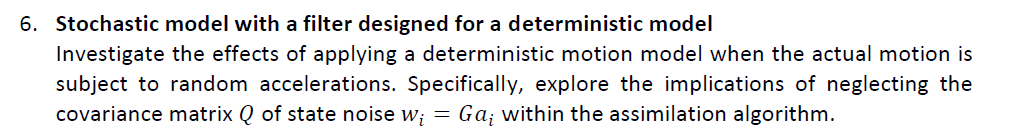

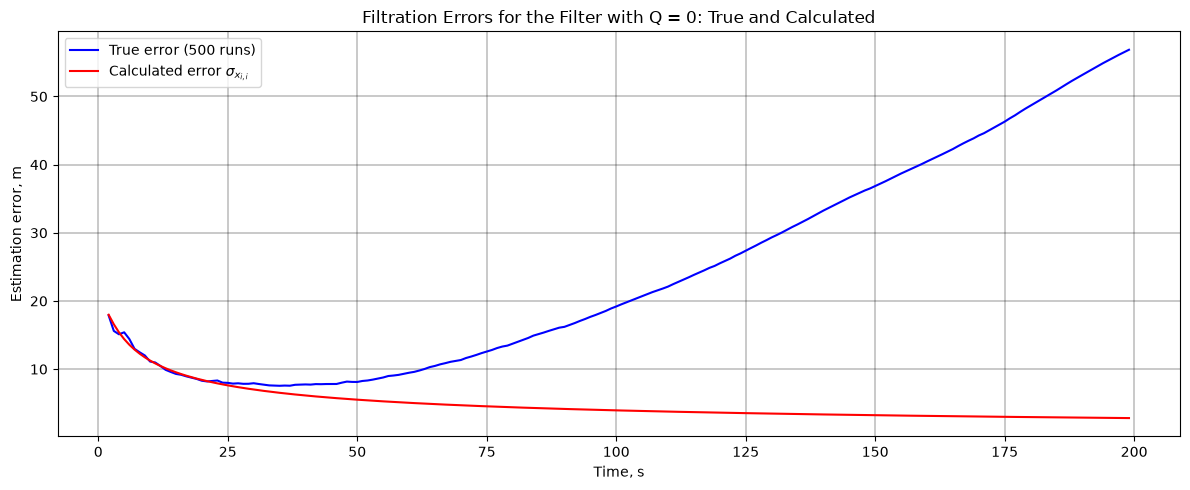

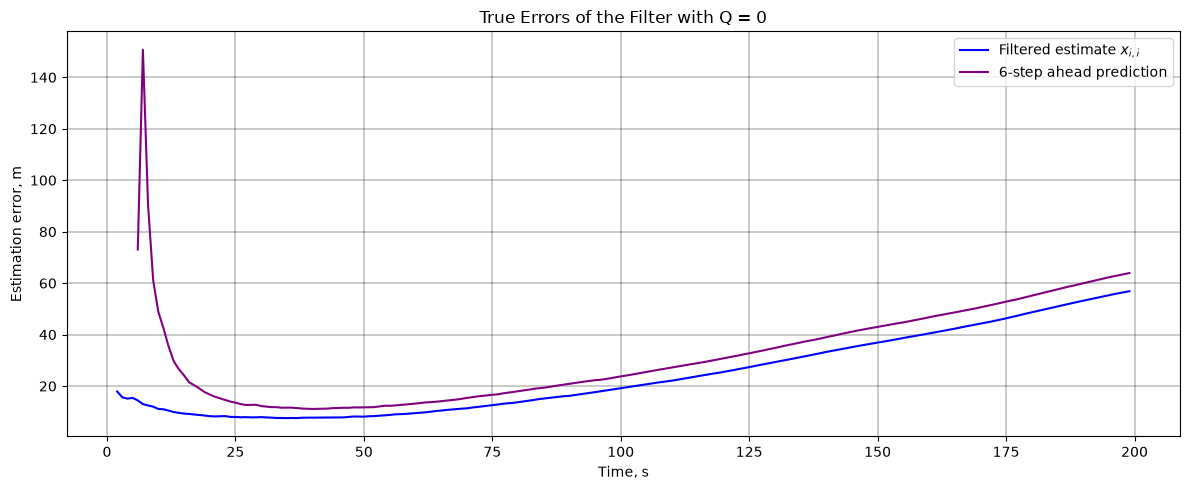

56.8576805307335 2.817569775521661 63.92393172038256


In [42]:
# stochastic trajectories (sigma_a = 0.2) but the filter is designed for the deterministic model (Q = 0)
final_err_filt_q0, _, final_err_pred_m_q0 = run_experiment(M_RUNS, SIGMA_A, Q_DET, P_0_0)

# calculated error of the filter with Q = 0 (the same as in the deterministic case): sigma_x_filt_det

# plot: true and calculated errors of the filtered estimate
plot_errors(
    [(final_err_filt_q0, "True error (500 runs)", "blue"),
     (sigma_x_filt_det, "Calculated error $\\sigma_{x_{i,i}}$", "red")],
    "Filtration Errors for the Filter with Q = 0: True and Calculated",
    step_size=T)

# plot: true errors of the filtered estimate and of the (m-1)-step ahead prediction
plot_errors(
    [(final_err_filt_q0, "Filtered estimate $x_{i,i}$", "blue"),
     (final_err_pred_m_q0, f"{M_PRED - 1}-step ahead prediction", "purple")],
    "True Errors of the Filter with Q = 0",
    step_size=T)

print(final_err_filt_q0[-1], sigma_x_filt_det[-1], final_err_pred_m_q0[-1])


Stochastic model with a filter designed for a deterministic model. The trajectories were generated with random accelerations ($\sigma_a = 0.2$ m/s²), while the filter was designed with $Q = 0$. During the first 25 s the true error of the filtered estimate is close to the calculated error $\sigma_{x_{i,i}}$. After that the two errors diverge: the calculated error keeps decreasing and reaches 2.8 m at the end of the observation interval, while the true error reaches a minimum of about 8 m and then grows continuously, up to 56.9 m. The error of the 6-step ahead prediction behaves similarly and reaches 63.9 m. Thus, the filter diverges.

The reason is that with $Q = 0$ the filter assumes that the raft moves with a constant velocity along a straight line. As a result, the prediction error covariance does not grow at the prediction step, the filter gain $K_i$ tends to zero, and the filter stops reacting to new measurements. In reality the random accelerations constantly change the velocity of the raft, and the true trajectory moves away from the straight line expected by the filter, while the filter does not correct its estimate.

The most dangerous consequence is that the calculated error is misleading: the filter reports a high accuracy (2.8 m) when the real error is 56.9 m, so the estimate cannot be trusted. For the rescue mission, the drone would plan the interception using a wrong position of the raft and would be sure that this position is accurate. This shows the importance of properly tuning the filter, in particular of including the state noise covariance matrix $Q$ that describes the uncertainty of the motion model, even if the model of the dynamics is approximately correct.

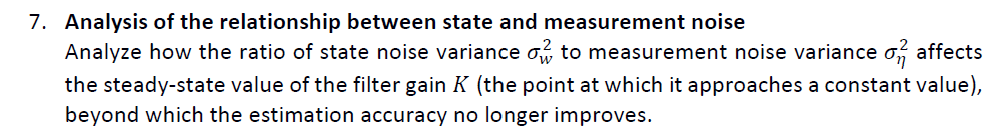

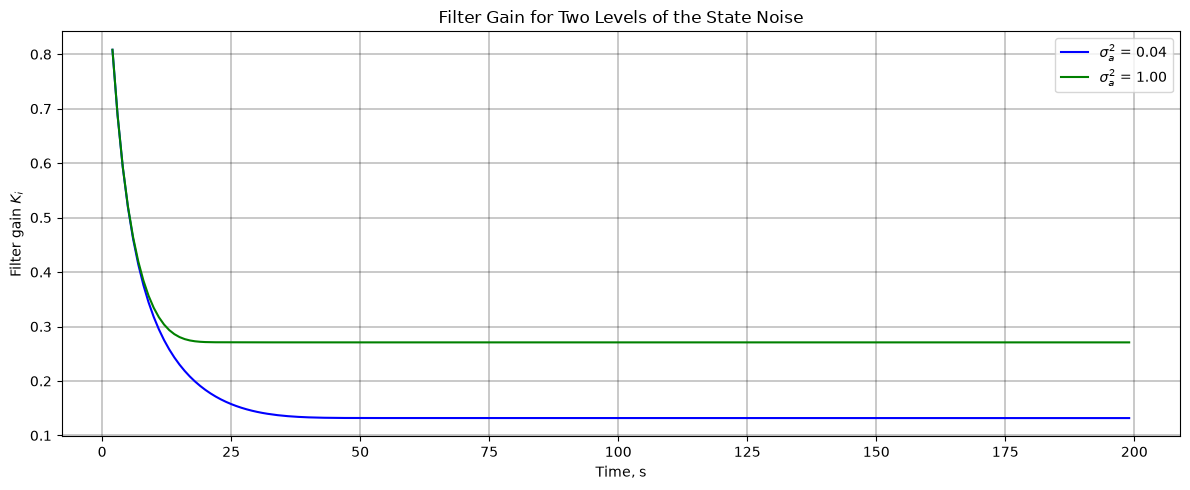

sigma_a^2 = 0.04: K = 0.1319, sigma = 7.26 m
sigma_a^2 = 1.00: K = 0.2709, sigma = 10.41 m


In [43]:
# steady-state filter gain for two levels of the state noise
VARIANCE_A_LARGE = 1.0
Q_LARGE = G @ G.T * VARIANCE_A_LARGE

# the filter gain does not depend on the measurements, so any measurements can be used
_, _, _, P_filt_large, K_large = kalman_filter(measured_trajectory_raft, PHI, H, Q_LARGE, R, X_0_0, P_0_0)
K_x_large = K_large[:, 0, 0]
sigma_x_filt_large = np.sqrt(P_filt_large[:, 0, 0])

plot_errors(
    [(K_x, f"$\\sigma_a^2$ = {VARIANCE_A:.2f}", "blue"),
     (K_x_large, f"$\\sigma_a^2$ = {VARIANCE_A_LARGE:.2f}", "green")],
    "Filter Gain for Two Levels of the State Noise",
    step_size=T, ylabel="Filter gain $K_i$")

print(f"sigma_a^2 = {VARIANCE_A:.2f}: K = {K_x[-1]:.4f}, sigma = {sigma_x_filt[-1]:.2f} m")
print(f"sigma_a^2 = {VARIANCE_A_LARGE:.2f}: K = {K_x_large[-1]:.4f}, sigma = {sigma_x_filt_large[-1]:.2f} m")

Relationship between state and measurement noise. For $\sigma_a^2 = 1$ (the ratio of the state noise variance to the measurement noise variance $\sigma_a^2 / \sigma_\eta^2 = 1/400 = 2.5 \cdot 10^{-3}$) the filter gain for the coordinate reaches a steady-state value of 0.271, while for $\sigma_a^2 = 0.2^2 = 0.04$ (the ratio $1 \cdot 10^{-4}$) it is 0.132. Thus, a larger ratio of the state noise to the measurement noise leads to a higher steady-state gain. In addition, with the larger state noise the gain becomes constant faster (after about 20 s instead of about 40 s), and the steady-state calculated error of the filtered estimate is larger: 10.41 m instead of 7.26 m.

The reason is that the larger state noise makes the motion of the raft less predictable. The state noise covariance matrix $Q$ is added to the prediction error covariance matrix $P_{i,i-1}$, so $P_{i,i-1}$ grows, the prediction becomes less reliable than the measurement, and the filter gain $K_i$, which balances the new measurement and the prediction, increases. A higher gain means that the filter puts more confidence in the measurements $z_i$ and less confidence in the model-based prediction. Since the model-based prediction is less accurate, the final accuracy of the estimate is also lower.

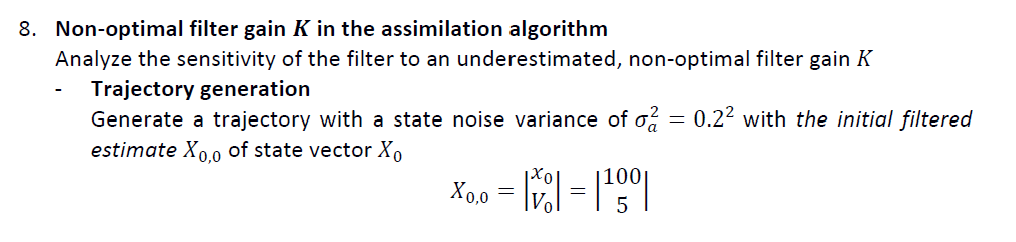

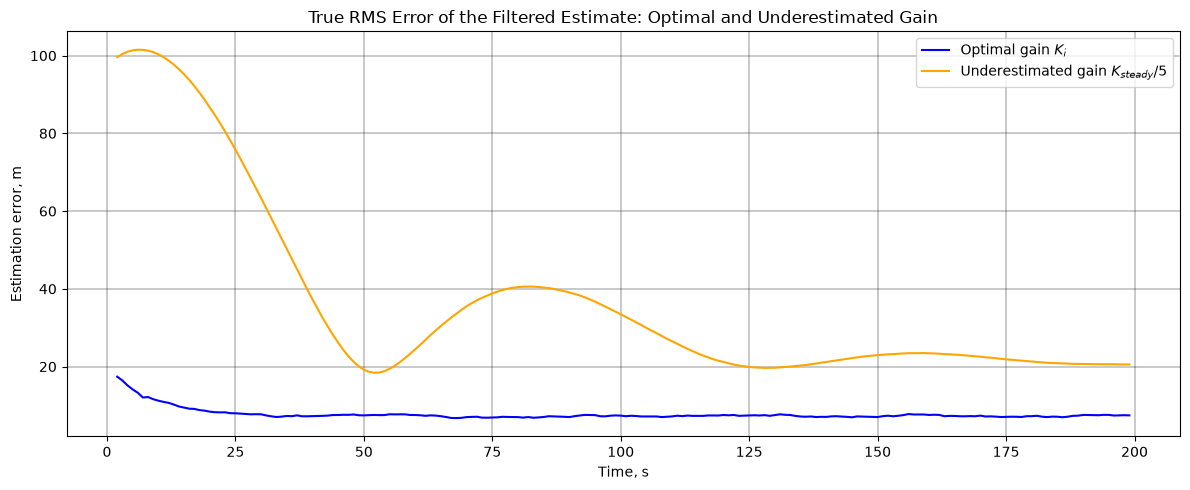

7.302719910980213 22.646146945453733


In [44]:
# filter with a fixed (given) gain instead of the optimal gain
def kalman_filter_fixed_gain(measurements, phi, h, k_fixed, x_0_0):
    size = measurements.size
    x_filt = np.zeros((size, 2, 1))
    x_prev = x_0_0

    for i in range(size):
        x_pred = phi @ x_prev                                      # prediction
        x_filt[i] = x_pred + k_fixed * (measurements[i] - h @ x_pred)   # filtration with the given gain
        x_prev = x_filt[i]

    return x_filt

# inaccurate initial filtered estimate
X_0_0_BAD = np.array([[100],
                      [5]])

# steady-state gain of the optimal filter (from the main case) and the underestimated gain
K_STEADY = K[-1]
K_UNDER = K_STEADY / 5

# true errors over 500 runs for both conditions
sq_err_opt = np.zeros((M_RUNS, SIZE))
sq_err_under = np.zeros((M_RUNS, SIZE))

for r in range(M_RUNS):
    true_traj, _ = generate_true_trajectory(SIZE, INITIAL_COORDINATE_M, INITIAL_VELOCITY_M_S, SIGMA_A, T)
    measured_traj = generate_measured_trajectory(true_traj, SIGMA_ETA)

    # condition 1: optimal gain
    _, _, x_filt_opt, _, _ = kalman_filter(measured_traj, PHI, H, Q, R, X_0_0_BAD, P_0_0)
    # condition 2: underestimated gain
    x_filt_under = kalman_filter_fixed_gain(measured_traj, PHI, H, K_UNDER, X_0_0_BAD)

    sq_err_opt[r] = (true_traj - x_filt_opt[:, 0, 0])**2
    sq_err_under[r] = (true_traj - x_filt_under[:, 0, 0])**2

final_err_opt = np.sqrt(np.sum(sq_err_opt, axis=0) / (M_RUNS - 1))
final_err_under = np.sqrt(np.sum(sq_err_under, axis=0) / (M_RUNS - 1))

plot_errors(
    [(final_err_opt, "Optimal gain $K_i$", "blue"),
     (final_err_under, "Underestimated gain $K_{steady}/5$", "orange")],
    "True RMS Error of the Filtered Estimate: Optimal and Underestimated Gain",
    step_size=T)

print(np.mean(final_err_opt[-100:]), np.mean(final_err_under[-100:]))

Non-optimal filter gain. The true error of the filter with the optimal gain decreases quickly from about 18 m to the steady-state level of 7.30 m within about 30 s, even though the initial filtered estimate $X_{0,0} = [100, 5]^T$ is far from the true initial state. The filter with the underestimated gain $K = K_{steady}/5$ reacts to the measurements too slowly: during the first 10 s its error remains at about 100 m, then it decreases with a strongly oscillating transient process (a minimum of about 19 m at 50 s and a new maximum of about 40 m at 80 s), and the steady-state error is 22.65 m, i.e. about 3.1 times larger than the error of the optimal filter (7.30 m).

The reason is that the gain determines how much the filter trusts the new measurement compared with its own prediction. The underestimated gain makes the filter trust the prediction too much: it keeps the wrong initial estimate for a long time and cannot follow the real changes of the raft’s velocity caused by the random accelerations. The optimal gain, calculated from $Q$ and $R$, gives the best balance between the prediction and the measurements and therefore the minimal error. This shows the importance of accurately tuning the Kalman filter: a non-optimal gain, even if it is constant and “reasonable”, leads to a significantly lower accuracy and a much longer transient process.